In [14]:

from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.manual_seed_all(SEED)

# Dataset paths
ROOT = Path(r"C:\Users\ASUS\Desktop\archive (1)")
IMAGE_DIR = ROOT / "Image"
MASK_DIR = ROOT / "Mask"

assert IMAGE_DIR.is_dir(), f"Image folder not found: {IMAGE_DIR}"
assert MASK_DIR.is_dir(), f"Mask folder not found: {MASK_DIR}"

print("Dataset folders verified!")


PyTorch: 2.5.1+cu121
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Dataset folders verified!


In [15]:

class FloodDataset(Dataset):
    def __init__(self, pairs, size=256):
        self.pairs = pairs
        self.image_resize = transforms.Resize((size, size))
        self.mask_resize = transforms.Resize(
            (size, size),
            interpolation=transforms.InterpolationMode.NEAREST
        )
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        image_path, mask_path = self.pairs[idx]

        with Image.open(image_path) as im:
            image = im.convert("RGB")
            image = self.to_tensor(self.image_resize(image))

        with Image.open(mask_path) as im:
            mask = im.convert("L")
            mask = np.array(self.mask_resize(mask), dtype=np.uint8)

        # Background = 0, flood = 1
        mask = torch.from_numpy(
            (mask >= 128).astype(np.float32)
        ).unsqueeze(0)

        return image, mask


image_map = {
    p.stem: p for p in IMAGE_DIR.iterdir() if p.is_file()
}
mask_map = {
    p.stem: p for p in MASK_DIR.iterdir() if p.is_file()
}

assert image_map.keys() == mask_map.keys(), (
    "Image and mask filenames do not match. Check the dataset."
)

ids = sorted(
    image_map.keys(),
    key=lambda x: int(x) if x.isdigit() else x
)

pairs = [(image_map[i], mask_map[i]) for i in ids]
dataset = FloodDataset(pairs)

print("Matched pairs:", len(dataset))

sample_image, sample_mask = dataset[0]
print("Image shape:", sample_image.shape)
print("Mask shape:", sample_mask.shape)
print("Mask values:", torch.unique(sample_mask).tolist())


Matched pairs: 290
Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Mask values: [0.0, 1.0]


In [16]:

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)


class UNet(nn.Module):
    def __init__(self, n_channels=3, n_classes=1):
        super().__init__()

        self.inc = DoubleConv(n_channels, 64)
        self.down1 = nn.Sequential(
            nn.MaxPool2d(2), DoubleConv(64, 128)
        )
        self.down2 = nn.Sequential(
            nn.MaxPool2d(2), DoubleConv(128, 256)
        )
        self.down3 = nn.Sequential(
            nn.MaxPool2d(2), DoubleConv(256, 512)
        )
        self.down4 = nn.Sequential(
            nn.MaxPool2d(2), DoubleConv(512, 1024)
        )

        self.up1 = nn.Upsample(
            scale_factor=2, mode="bilinear", align_corners=True
        )
        self.conv_up1 = DoubleConv(1024 + 512, 512)

        self.up2 = nn.Upsample(
            scale_factor=2, mode="bilinear", align_corners=True
        )
        self.conv_up2 = DoubleConv(512 + 256, 256)

        self.up3 = nn.Upsample(
            scale_factor=2, mode="bilinear", align_corners=True
        )
        self.conv_up3 = DoubleConv(256 + 128, 128)

        self.up4 = nn.Upsample(
            scale_factor=2, mode="bilinear", align_corners=True
        )
        self.conv_up4 = DoubleConv(128 + 64, 64)

        self.outc = nn.Conv2d(64, n_classes, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        x = self.up1(x5)
        x = torch.cat([x4, x], dim=1)
        x = self.conv_up1(x)

        x = self.up2(x)
        x = torch.cat([x3, x], dim=1)
        x = self.conv_up2(x)

        x = self.up3(x)
        x = torch.cat([x2, x], dim=1)
        x = self.conv_up3(x)

        x = self.up4(x)
        x = torch.cat([x1, x], dim=1)
        x = self.conv_up4(x)

        return self.outc(x)


# Check that the architecture accepts a sample image
model = UNet(n_channels=3, n_classes=1).to(device)

with torch.no_grad():
    sample_output = model(sample_image.unsqueeze(0).to(device))

print("Model output shape:", sample_output.shape)
print("U-Net architecture check passed!")


Model output shape: torch.Size([1, 1, 256, 256])
U-Net architecture check passed!


In [17]:

n = len(dataset)
n_train = int(0.70 * n)
n_val = int(0.15 * n)
n_test = n - n_train - n_val

train_ds, val_ds, test_ds = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

# Conservative batch size for the large U-Net
batch_size = 1

train_loader = DataLoader(
    train_ds, batch_size=batch_size,
    shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_ds, batch_size=batch_size,
    shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_ds, batch_size=batch_size,
    shuffle=False, num_workers=0
)

print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Test images:", len(test_ds))


Training images: 203
Validation images: 43
Test images: 44


In [18]:

import copy

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# Save beside the notebook, in your project folder
CHECKPOINT = Path.cwd() / "flood_model_final.pth"
best_val_loss = float("inf")
best_weights = None

# Use mixed precision on CUDA to reduce GPU memory usage
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

for epoch in range(3):
    model.train()
    total_train_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_train_loss += loss.item() * images.size(0)

    train_loss = total_train_loss / len(train_ds)

    model.eval()
    total_val_loss = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                logits = model(images)
                loss = criterion(logits, masks)

            total_val_loss += loss.item() * images.size(0)

    val_loss = total_val_loss / len(val_ds)

    print(
        f"Epoch {epoch + 1}/3 | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if np.isfinite(val_loss) and val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        torch.save(best_weights, CHECKPOINT)
        print("Checkpoint saved:", CHECKPOINT)

if best_weights is None:
    raise RuntimeError("No valid checkpoint was saved.")

model.load_state_dict(best_weights)
print("Training smoke test complete.")


Epoch 1/3 | Train loss: 0.4774 | Validation loss: 0.4059
Checkpoint saved: c:\Users\ASUS\Downloads\DL_Project\Satellite-Flood-Detection-UNet\flood_model_final.pth
Epoch 2/3 | Train loss: 0.4196 | Validation loss: 0.3840
Checkpoint saved: c:\Users\ASUS\Downloads\DL_Project\Satellite-Flood-Detection-UNet\flood_model_final.pth
Epoch 3/3 | Train loss: 0.3990 | Validation loss: 0.3719
Checkpoint saved: c:\Users\ASUS\Downloads\DL_Project\Satellite-Flood-Detection-UNet\flood_model_final.pth
Training smoke test complete.


In [19]:

import matplotlib.pyplot as plt
import torch

model.eval()

total_intersection = 0
total_union = 0
total_correct = 0
total_pixels = 0
total_dice = 0
total_iou = 0
num_images = 0

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).float()

        for pred, target in zip(predictions, masks):
            pred_bool = pred.bool()
            target_bool = target.bool()

            intersection = (pred_bool & target_bool).sum().item()
            union = (pred_bool | target_bool).sum().item()
            pred_count = pred_bool.sum().item()
            target_count = target_bool.sum().item()

            # Dice and IoU, including the empty-mask case
            dice = (
                2 * intersection / (pred_count + target_count)
                if pred_count + target_count > 0 else 1.0
            )
            iou = (
                intersection / union if union > 0 else 1.0
            )

            total_dice += dice
            total_iou += iou
            total_intersection += intersection
            total_union += union

        total_correct += (predictions == masks).sum().item()
        total_pixels += masks.numel()
        num_images += images.size(0)

print(f"Test images: {num_images}")
print(f"Mean Dice: {total_dice / num_images:.4f}")
print(f"Mean IoU: {total_iou / num_images:.4f}")
print(f"Pixel accuracy: {total_correct / total_pixels:.4f}")
print(
    "Global IoU:",
    round(total_intersection / total_union, 4)
    if total_union else 1.0
)


Test images: 44
Mean Dice: 0.7802
Mean IoU: 0.6728
Pixel accuracy: 0.8493
Global IoU: 0.6884


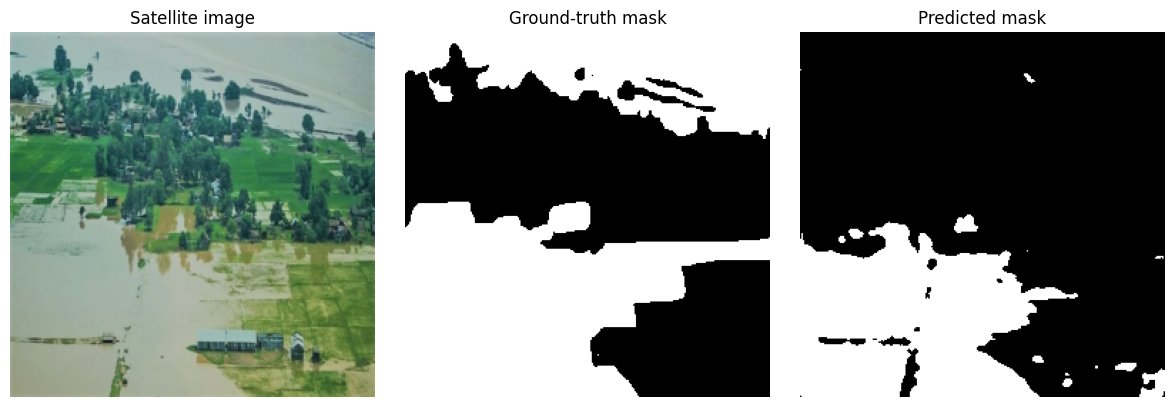

In [20]:

model.eval()

images, masks = next(iter(test_loader))

with torch.no_grad():
    logits = model(images.to(device))
    probabilities = torch.sigmoid(logits).cpu()
    predictions = (probabilities >= 0.5).float()

n_show = min(4, len(images))
fig, axes = plt.subplots(n_show, 3, figsize=(12, 4 * n_show))

if n_show == 1:
    axes = axes.reshape(1, 3)

for i in range(n_show):
    image = images[i].permute(1, 2, 0).numpy()
    target = masks[i, 0].numpy()
    pred = predictions[i, 0].numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Satellite image")

    axes[i, 1].imshow(target, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground-truth mask")

    axes[i, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title("Predicted mask")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


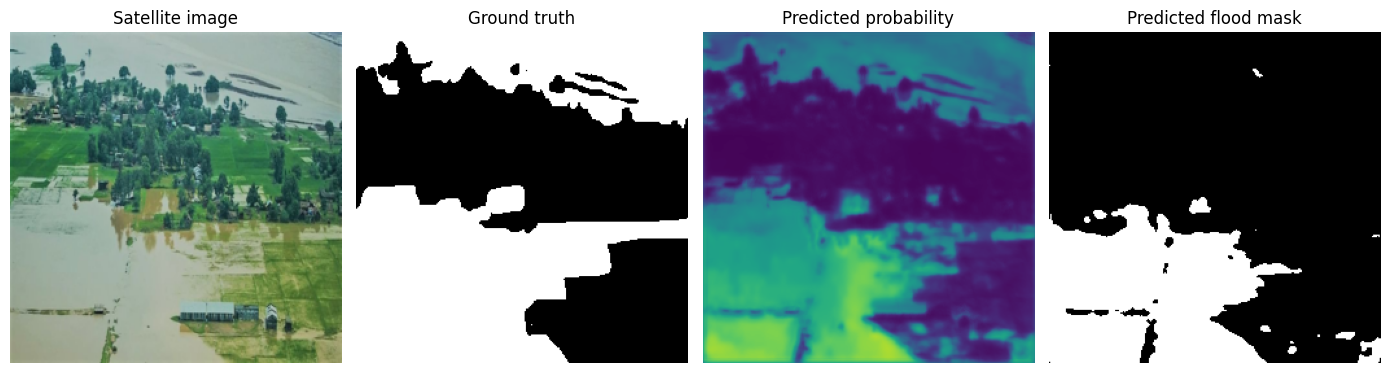

In [21]:

model.eval()

images, masks = next(iter(test_loader))

with torch.no_grad():
    logits = model(images.to(device))
    probabilities = torch.sigmoid(logits).cpu()
    predictions = (probabilities >= 0.5).float()

n = min(4, len(images))
fig, axes = plt.subplots(n, 4, figsize=(14, 4 * n))

if n == 1:
    axes = axes.reshape(1, 4)

for i in range(n):
    image = images[i].permute(1, 2, 0).numpy()
    target = masks[i, 0].numpy()
    prob = probabilities[i, 0].numpy()
    pred = predictions[i, 0].numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Satellite image")

    axes[i, 1].imshow(target, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
    axes[i, 2].set_title("Predicted probability")

    axes[i, 3].imshow(pred, cmap="gray", vmin=0, vmax=1)
    axes[i, 3].set_title("Predicted flood mask")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [22]:

import copy
import torch
import matplotlib.pyplot as plt
from pathlib import Path

# Fine-tune the current model
model = model.to(device)

criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

MAX_EPOCHS = 20
PATIENCE = 4

best_val_loss = float("inf")
epochs_without_improvement = 0
best_state = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [],
    "val_loss": []
}

checkpoint_path = Path.cwd() / "flood_model_final.pth"

for epoch in range(MAX_EPOCHS):
    # ---------------- Training ----------------
    model.train()
    train_loss_sum = 0.0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=use_amp
        ):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_sum += loss.item() * images.size(0)

    train_loss = train_loss_sum / len(train_loader.dataset)

    # ---------------- Validation ----------------
    model.eval()
    val_loss_sum = 0.0

    with torch.inference_mode():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                logits = model(images)
                loss = criterion(logits, masks)

            val_loss_sum += loss.item() * images.size(0)

    val_loss = val_loss_sum / len(val_loader.dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # Save the best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, checkpoint_path)
        epochs_without_improvement = 0
        print("  -> Best checkpoint saved")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation loss stopped improving.")
        break

# Restore the best validation checkpoint
model.load_state_dict(best_state)
model.eval()

print(f"\nBest validation loss: {best_val_loss:.4f}")
print(f"Checkpoint saved at: {checkpoint_path}")


Epoch 01/20 | Train Loss: 0.3849 | Val Loss: 0.4215
  -> Best checkpoint saved
Epoch 02/20 | Train Loss: 0.3638 | Val Loss: 0.3887
  -> Best checkpoint saved
Epoch 03/20 | Train Loss: 0.3435 | Val Loss: 0.3646
  -> Best checkpoint saved
Epoch 04/20 | Train Loss: 0.3488 | Val Loss: 0.3582
  -> Best checkpoint saved
Epoch 05/20 | Train Loss: 0.3285 | Val Loss: 0.4900
Epoch 06/20 | Train Loss: 0.3284 | Val Loss: 0.3961
Epoch 07/20 | Train Loss: 0.3226 | Val Loss: 0.4213
Epoch 08/20 | Train Loss: 0.3071 | Val Loss: 0.3514
  -> Best checkpoint saved
Epoch 09/20 | Train Loss: 0.3135 | Val Loss: 0.4204
Epoch 10/20 | Train Loss: 0.2994 | Val Loss: 0.4084
Epoch 11/20 | Train Loss: 0.2933 | Val Loss: 0.3674
Epoch 12/20 | Train Loss: 0.2969 | Val Loss: 0.4148
Early stopping: validation loss stopped improving.

Best validation loss: 0.3514
Checkpoint saved at: c:\Users\ASUS\Downloads\DL_Project\Satellite-Flood-Detection-UNet\flood_model_final.pth


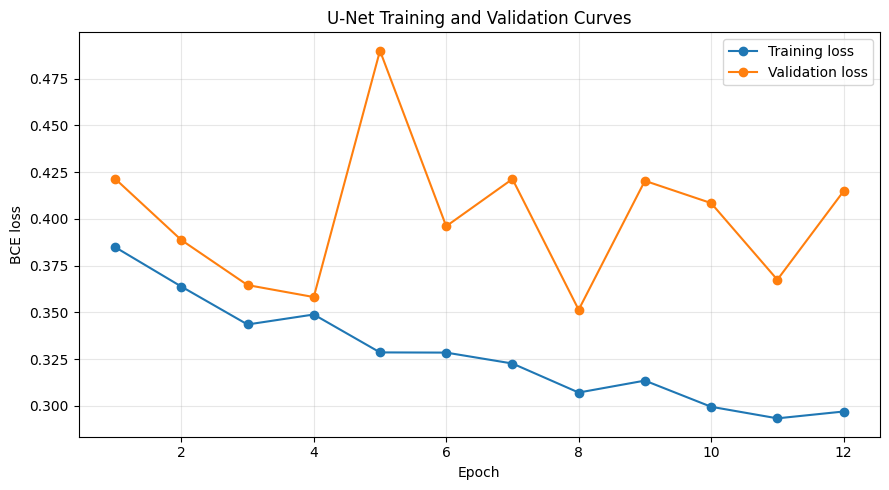

In [23]:

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("U-Net Training and Validation Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:

import torch
import numpy as np
from pathlib import Path

# Load the best saved checkpoint
checkpoint_path = Path.cwd() / "flood_model_final.pth"
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model.to(device)
model.eval()

tp = fp = fn = tn = 0

with torch.inference_mode():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5)
        targets = (masks >= 0.5)

        tp += (predictions & targets).sum().item()
        fp += (predictions & ~targets).sum().item()
        fn += (~predictions & targets).sum().item()
        tn += (~predictions & ~targets).sum().item()

# Calculate global pixel-level metrics
epsilon = 1e-8

precision = tp / (tp + fp + epsilon)
recall = tp / (tp + fn + epsilon)
f1 = 2 * precision * recall / (precision + recall + epsilon)
iou = tp / (tp + fp + fn + epsilon)
accuracy = (tp + tn) / (tp + tn + fp + fn + epsilon)

print("FINAL TEST SET RESULTS")
print("-" * 35)
print(f"Precision:       {precision:.4f}")
print(f"Recall:          {recall:.4f}")
print(f"F1 / Dice:       {f1:.4f}")
print(f"Global IoU:      {iou:.4f}")
print(f"Pixel accuracy:  {accuracy:.4f}")
print(f"Test images:     {len(test_loader.dataset)}")


FINAL TEST SET RESULTS
-----------------------------------
Precision:       0.8921
Recall:          0.6794
F1 / Dice:       0.7714
Global IoU:      0.6278
Pixel accuracy:  0.8288
Test images:     44


VALIDATION THRESHOLD COMPARISON
-----------------------------------------------------------------
Threshold   Precision   Recall      F1/Dice     IoU         
0.20        0.7402      0.8630      0.7969      0.6624      
0.25        0.7815      0.8356      0.8076      0.6774      
0.30        0.8135      0.8093      0.8114      0.6827      
0.35        0.8407      0.7836      0.8112      0.6823      
0.40        0.8647      0.7566      0.8070      0.6765      
0.45        0.8854      0.7269      0.7983      0.6644      
0.50        0.9026      0.6973      0.7868      0.6485      
0.55        0.9160      0.6685      0.7729      0.6299      
0.60        0.9278      0.6378      0.7559      0.6076      
0.65        0.9381      0.6030      0.7341      0.5799      
0.70        0.9477      0.5620      0.7055      0.5450      
0.75        0.9564      0.5108      0.6659      0.4991      
0.80        0.9673      0.4513      0.6155      0.4445      

Best validation F1 threshold: 0.30
Validation F

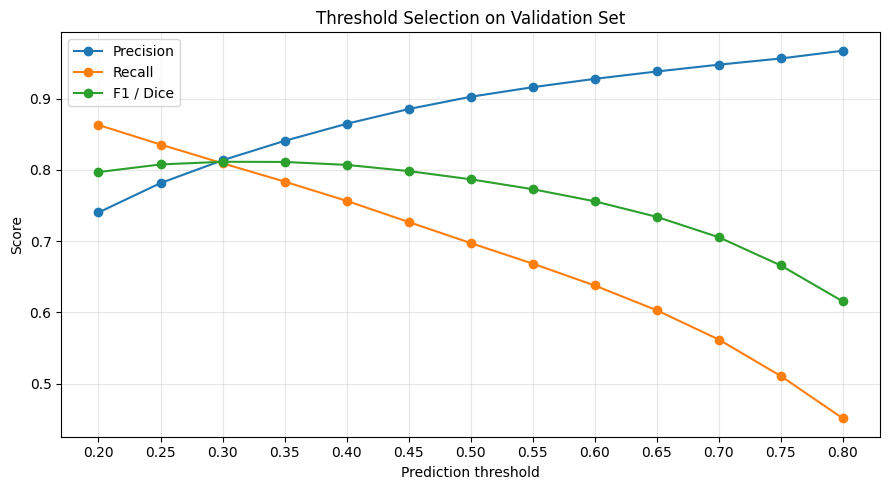

In [25]:

import torch
import numpy as np
import matplotlib.pyplot as plt

thresholds = np.arange(0.20, 0.81, 0.05)
results = []

model.eval()

with torch.inference_mode():
    for threshold in thresholds:
        tp = fp = fn = 0

        for images, masks in val_loader:
            images = images.to(device)
            targets = masks.to(device) >= 0.5

            probabilities = torch.sigmoid(model(images))
            predictions = probabilities >= float(threshold)

            tp += (predictions & targets).sum().item()
            fp += (predictions & ~targets).sum().item()
            fn += (~predictions & targets).sum().item()

        precision = tp / (tp + fp + 1e-8)
        recall = tp / (tp + fn + 1e-8)
        f1 = 2 * precision * recall / (precision + recall + 1e-8)
        iou = tp / (tp + fp + fn + 1e-8)

        results.append({
            "threshold": float(threshold),
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "iou": iou
        })

print("VALIDATION THRESHOLD COMPARISON")
print("-" * 65)
print(f"{'Threshold':<12}{'Precision':<12}{'Recall':<12}{'F1/Dice':<12}{'IoU':<12}")

for r in results:
    print(
        f"{r['threshold']:<12.2f}"
        f"{r['precision']:<12.4f}"
        f"{r['recall']:<12.4f}"
        f"{r['f1']:<12.4f}"
        f"{r['iou']:<12.4f}"
    )

best = max(results, key=lambda r: r["f1"])
print(f"\nBest validation F1 threshold: {best['threshold']:.2f}")
print(f"Validation F1: {best['f1']:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(thresholds, [r["precision"] for r in results],
         marker="o", label="Precision")
plt.plot(thresholds, [r["recall"] for r in results],
         marker="o", label="Recall")
plt.plot(thresholds, [r["f1"] for r in results],
         marker="o", label="F1 / Dice")
plt.xlabel("Prediction threshold")
plt.ylabel("Score")
plt.title("Threshold Selection on Validation Set")
plt.xticks(thresholds.round(2))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [26]:

import torch
import copy
from pathlib import Path

# Create a fresh model, independent of the fine-tuned model
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

baseline_model = UNet(n_channels=3, n_classes=1).to(device)

criterion = torch.nn.BCEWithLogitsLoss()
baseline_optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=1e-4
)

use_amp = device.type == "cuda"
baseline_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

best_val_loss = float("inf")
baseline_best_state = copy.deepcopy(baseline_model.state_dict())

for epoch in range(3):
    baseline_model.train()
    train_sum = 0.0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        baseline_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=use_amp
        ):
            logits = baseline_model(images)
            loss = criterion(logits, masks)

        baseline_scaler.scale(loss).backward()
        baseline_scaler.step(baseline_optimizer)
        baseline_scaler.update()

        train_sum += loss.item() * images.size(0)

    train_loss = train_sum / len(train_loader.dataset)

    baseline_model.eval()
    val_sum = 0.0

    with torch.inference_mode():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                logits = baseline_model(images)
                loss = criterion(logits, masks)

            val_sum += loss.item() * images.size(0)

    val_loss = val_sum / len(val_loader.dataset)

    print(
        f"Baseline epoch {epoch + 1}/3 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        baseline_best_state = copy.deepcopy(
            baseline_model.state_dict()
        )

# Save to a NEW file; never overwrite the current app checkpoint
baseline_path = Path.cwd() / "flood_model_baseline.pth"
torch.save(baseline_best_state, baseline_path)

print("\nBaseline checkpoint saved to:", baseline_path)
print("Best baseline validation loss:", round(best_val_loss, 4))


Baseline epoch 1/3 | Train Loss: 0.4777 | Val Loss: 0.3912
Baseline epoch 2/3 | Train Loss: 0.4196 | Val Loss: 0.3607
Baseline epoch 3/3 | Train Loss: 0.3984 | Val Loss: 0.3834

Baseline checkpoint saved to: c:\Users\ASUS\Downloads\DL_Project\Satellite-Flood-Detection-UNet\flood_model_baseline.pth
Best baseline validation loss: 0.3607


In [27]:

import torch
from pathlib import Path

project_dir = Path.cwd()

baseline_path = project_dir / "flood_model_baseline.pth"
finetuned_path = project_dir / "flood_model_finetuned_backup.pth"

def evaluate_checkpoint(checkpoint_path, threshold=0.30):
    model_eval = UNet(n_channels=3, n_classes=1).to(device)

    state = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
    model_eval.load_state_dict(state)
    model_eval.eval()

    tp = fp = fn = tn = 0

    with torch.inference_mode():
        for images, masks in test_loader:
            images = images.to(device)
            targets = masks.to(device) >= 0.5

            probabilities = torch.sigmoid(model_eval(images))
            predictions = probabilities >= threshold

            tp += (predictions & targets).sum().item()
            fp += (predictions & ~targets).sum().item()
            fn += (~predictions & targets).sum().item()
            tn += (~predictions & ~targets).sum().item()

    eps = 1e-8
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    dice = 2 * tp / (2 * tp + fp + fn + eps)
    iou = tp / (tp + fp + fn + eps)
    accuracy = (tp + tn) / (tp + tn + fp + fn + eps)

    return {
        "Precision": precision,
        "Recall": recall,
        "Dice/F1": dice,
        "Global IoU": iou,
        "Pixel Accuracy": accuracy
    }


baseline_results = evaluate_checkpoint(baseline_path)
finetuned_results = evaluate_checkpoint(finetuned_path)

print("TEST SET COMPARISON — threshold = 0.30")
print("-" * 75)
print(f"{'Metric':<20}{'Baseline':>15}{'Fine-tuned':>15}")
print("-" * 50)

for metric in baseline_results:
    print(
        f"{metric:<20}"
        f"{baseline_results[metric]:>15.4f}"
        f"{finetuned_results[metric]:>15.4f}"
    )

print("\nTest images:", len(test_loader.dataset))


TEST SET COMPARISON — threshold = 0.30
---------------------------------------------------------------------------
Metric                     Baseline     Fine-tuned
--------------------------------------------------
Precision                    0.7141         0.8166
Recall                       0.8763         0.8006
Dice/F1                      0.7869         0.8085
Global IoU                   0.6487         0.6786
Pixel Accuracy               0.7982         0.8388

Test images: 44


In [3]:

import torch
from torch.utils.data import DataLoader, random_split
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset

# Dataset location used earlier
ROOT = Path(r"C:\Users\ASUS\Desktop\archive (1)")

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

mask_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.PILToTensor()
])

class FloodDataset(Dataset):
    def __init__(self, root):
        self.root = Path(root)
        self.image_dir = self.root / "Image"
        self.mask_dir = self.root / "Mask"

        self.pairs = []
        for image_path in sorted(self.image_dir.glob("*")):
            if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
                continue

            mask_path = self.mask_dir / f"{image_path.stem}.png"
            if mask_path.exists():
                self.pairs.append((image_path, mask_path))

        if not self.pairs:
            raise RuntimeError(
                f"No image/mask pairs found. Check dataset path: {self.root}"
            )

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image = transform(image)
        mask = mask_transform(mask).float() / 255.0
        mask = (mask >= (128.0 / 255.0)).float()

        return image, mask

dataset = FloodDataset(ROOT)

# Reproduce the 203/43/44 split with seed 42
generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset, test_dataset = random_split(
    dataset, [203, 43, 44], generator=generator
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dataset size:", len(dataset))
print("Test images:", len(test_dataset))
print("Device:", device)


Dataset size: 290
Test images: 44
Device: cuda


UNet imported successfully.
Device: cuda


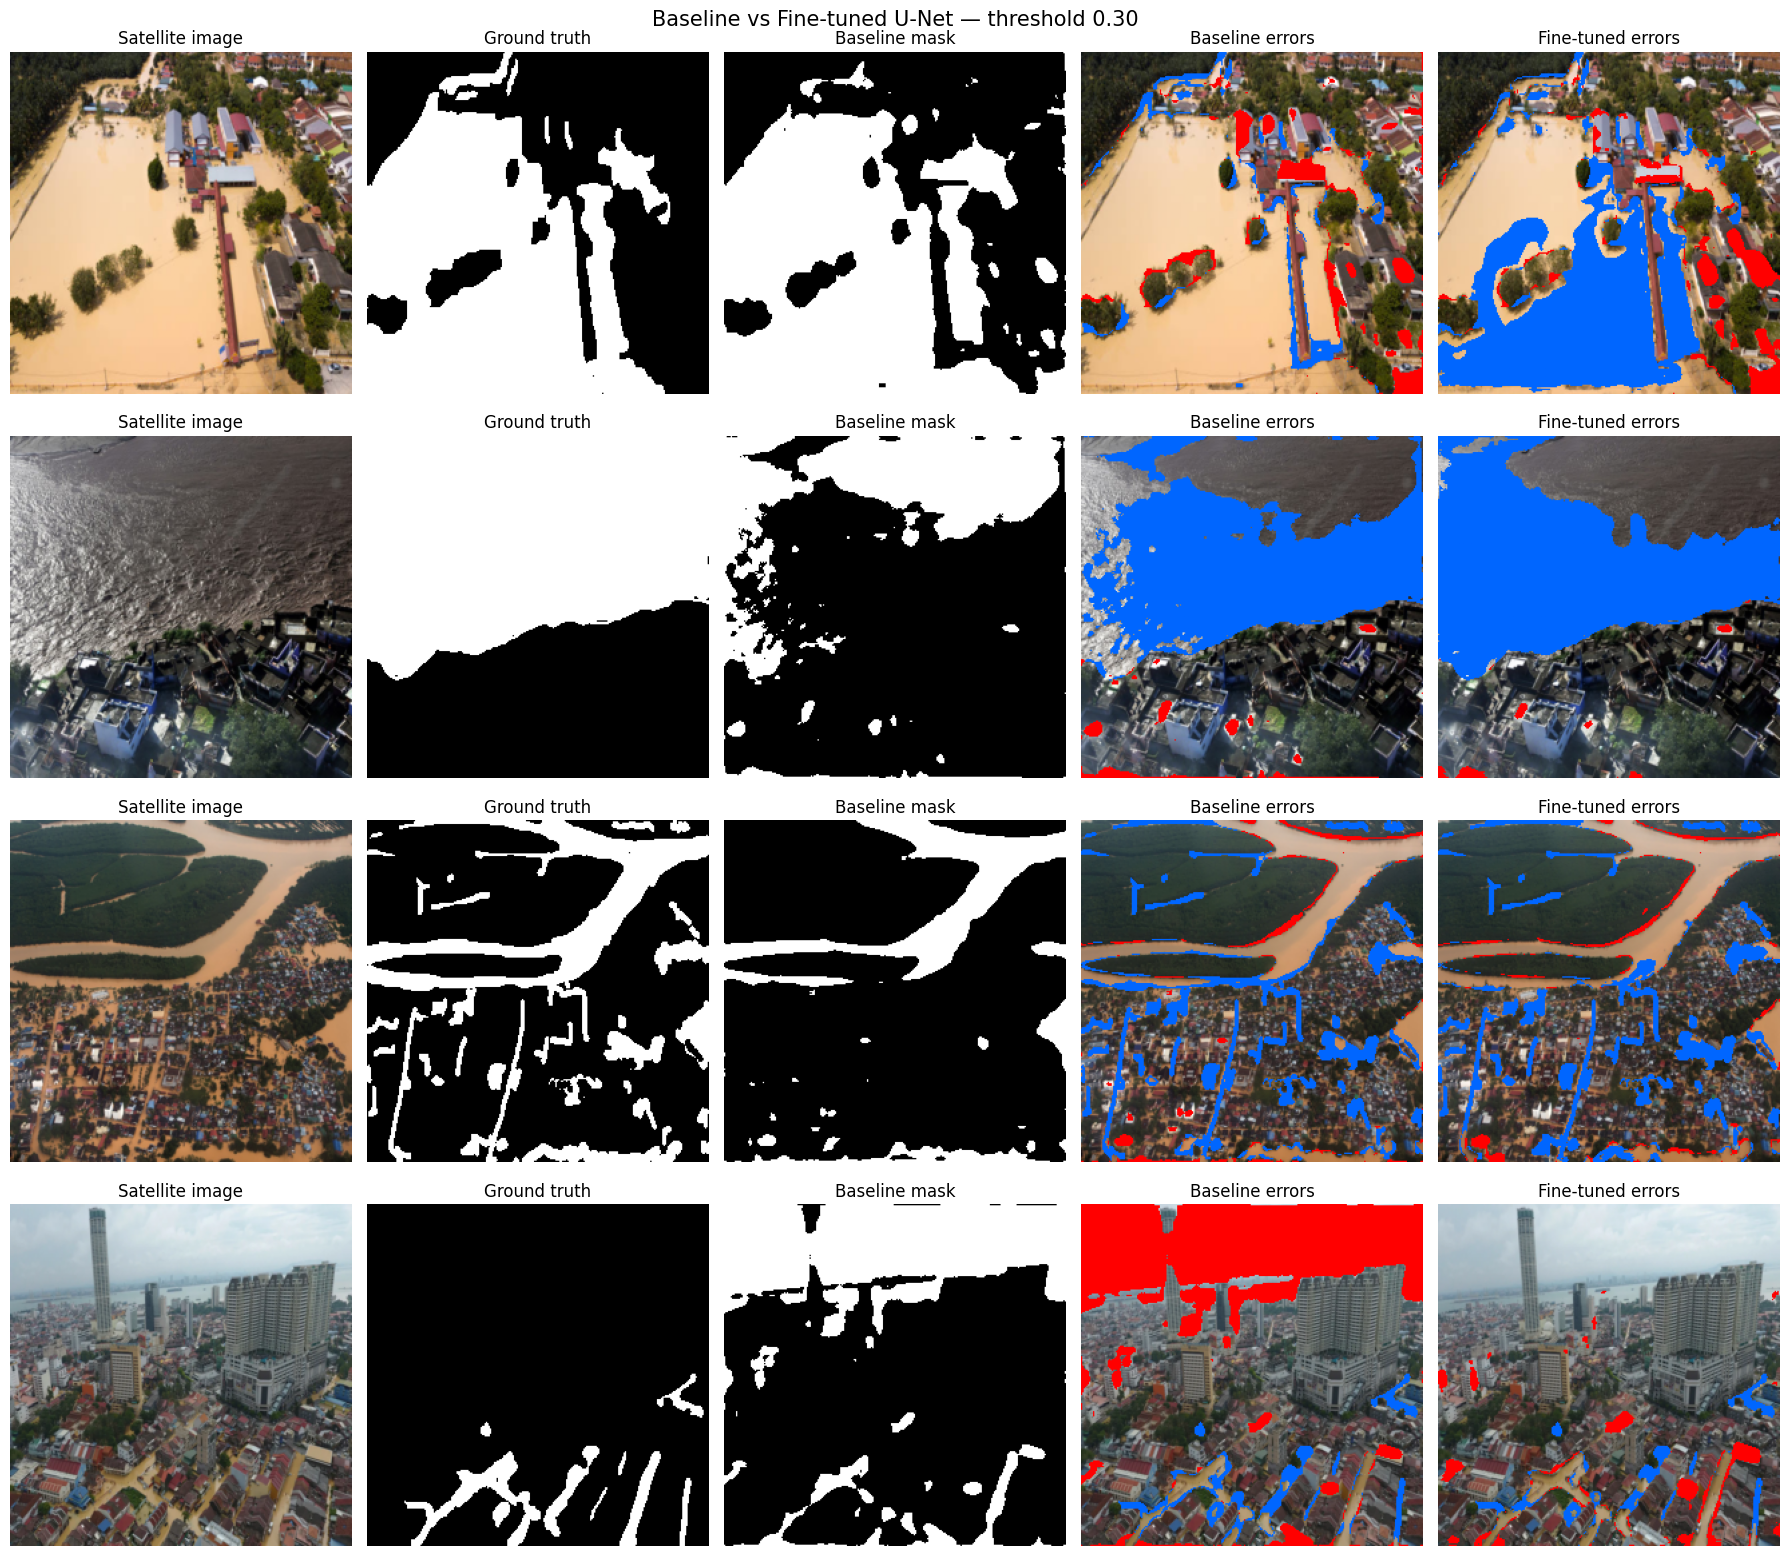

In [4]:


# Restore the imports and model definition in this notebook session
import torch
import matplotlib.pyplot as plt
from pathlib import Path

from model import UNet

# Re-establish the device if needed
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("UNet imported successfully.")
print("Device:", device)


project_dir = Path.cwd()
threshold = 0.30

# Load both checkpoints independently
baseline_model = UNet(n_channels=3, n_classes=1).to(device)
finetuned_model = UNet(n_channels=3, n_classes=1).to(device)

baseline_model.load_state_dict(
    torch.load(
        project_dir / "flood_model_baseline.pth",
        map_location=device,
        weights_only=True
    )
)

finetuned_model.load_state_dict(
    torch.load(
        project_dir / "flood_model_finetuned_backup.pth",
        map_location=device,
        weights_only=True
    )
)

baseline_model.eval()
finetuned_model.eval()

# Collect four test examples
images, masks = next(iter(test_loader))

with torch.inference_mode():
    x = images.to(device)

    baseline_probs = torch.sigmoid(baseline_model(x)).cpu()
    finetuned_probs = torch.sigmoid(finetuned_model(x)).cpu()

baseline_preds = (baseline_probs >= threshold).float()
finetuned_preds = (finetuned_probs >= threshold).float()

n = min(4, len(images))
fig, axes = plt.subplots(n, 5, figsize=(18, 4 * n))

if n == 1:
    axes = axes.reshape(1, 5)

for i in range(n):
    image = images[i].permute(1, 2, 0).numpy()
    target = masks[i, 0].numpy()
    base = baseline_preds[i, 0].numpy()
    fine = finetuned_preds[i, 0].numpy()

    # Red: false positives; blue: missed flood pixels
    base_errors = image.copy()
    base_fp = (base == 1) & (target == 0)
    base_fn = (base == 0) & (target == 1)
    base_errors[base_fp] = [1.0, 0.0, 0.0]
    base_errors[base_fn] = [0.0, 0.4, 1.0]

    fine_errors = image.copy()
    fine_fp = (fine == 1) & (target == 0)
    fine_fn = (fine == 0) & (target == 1)
    fine_errors[fine_fp] = [1.0, 0.0, 0.0]
    fine_errors[fine_fn] = [0.0, 0.4, 1.0]

    panels = [
        (image, "Satellite image"),
        (target, "Ground truth"),
        (base, "Baseline mask"),
        (base_errors, "Baseline errors"),
        (fine_errors, "Fine-tuned errors")
    ]

    for j, (data, title) in enumerate(panels):
        axes[i, j].imshow(
            data,
            cmap="gray" if j in [1, 2] else None,
            vmin=0 if j in [1, 2] else None,
            vmax=1 if j in [1, 2] else None
        )
        axes[i, j].set_title(title)
        axes[i, j].axis("off")

plt.suptitle(
    "Baseline vs Fine-tuned U-Net — threshold 0.30",
    fontsize=15
)
plt.tight_layout()
plt.show()


In [6]:

from torch.utils.data import DataLoader, random_split

# Recreate the same seeded 203/43/44 dataset split
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [203, 43, 44],
    generator=generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("All loaders recreated successfully.")


Train images: 203
Validation images: 43
Test images: 44
All loaders recreated successfully.


In [7]:

import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path

# Apply identical spatial transformations to image and mask
class AugmentedDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        image, mask = self.base_dataset[index]

        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[2])
            mask = torch.flip(mask, dims=[2])

        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[1])
            mask = torch.flip(mask, dims=[1])

        # Rotate both tensors by the same multiple of 90 degrees
        k = torch.randint(0, 4, (1,)).item()
        image = torch.rot90(image, k, dims=[1, 2])
        mask = torch.rot90(mask, k, dims=[1, 2])

        return image, mask


# Reproducible experiment setup
torch.manual_seed(123)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(123)

augmented_train_loader = DataLoader(
    AugmentedDataset(train_dataset),
    batch_size=1,
    shuffle=True,
    num_workers=0
)

aug_model = UNet(n_channels=3, n_classes=1).to(device)
optimizer = torch.optim.Adam(aug_model.parameters(), lr=1e-4)
bce_loss = nn.BCEWithLogitsLoss()

def dice_loss_fn(logits, targets, smooth=1.0):
    probabilities = torch.sigmoid(logits)
    probabilities = probabilities.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (probabilities * targets).sum(dim=1)
    denominator = probabilities.sum(dim=1) + targets.sum(dim=1)

    dice = (2 * intersection + smooth) / (denominator + smooth)
    return 1 - dice.mean()

def combined_loss(logits, targets):
    return 0.5 * bce_loss(logits, targets) + 0.5 * dice_loss_fn(
        logits, targets
    )

best_val_loss = float("inf")
best_state = copy.deepcopy(aug_model.state_dict())
patience = 3
stale_epochs = 0
max_epochs = 10

amp_enabled = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

for epoch in range(max_epochs):
    aug_model.train()
    train_sum = 0.0

    for images, masks in augmented_train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type, enabled=amp_enabled
        ):
            logits = aug_model(images)
            loss = combined_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        train_sum += loss.item() * images.size(0)

    train_loss = train_sum / len(augmented_train_loader.dataset)

    aug_model.eval()
    val_sum = 0.0

    with torch.inference_mode():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)

            with torch.autocast(
                device_type=device.type, enabled=amp_enabled
            ):
                logits = aug_model(images)
                loss = combined_loss(logits, masks)

            val_sum += loss.item() * images.size(0)

    val_loss = val_sum / len(val_loader.dataset)

    print(
        f"Augmented epoch {epoch + 1}/{max_epochs} | "
        f"Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(aug_model.state_dict())
        torch.save(
            best_state,
            Path.cwd() / "flood_model_augmented.pth"
        )
        stale_epochs = 0
        print("  -> Best augmented checkpoint saved")
    else:
        stale_epochs += 1

    if stale_epochs >= patience:
        print("Early stopping.")
        break

aug_model.load_state_dict(best_state)
aug_model.eval()

print(f"Best augmented validation loss: {best_val_loss:.4f}")


Augmented epoch 1/10 | Train loss: 0.4302 | Val loss: 0.3858
  -> Best augmented checkpoint saved
Augmented epoch 2/10 | Train loss: 0.3811 | Val loss: 0.4994
Augmented epoch 3/10 | Train loss: 0.3556 | Val loss: 0.3729
  -> Best augmented checkpoint saved
Augmented epoch 4/10 | Train loss: 0.3476 | Val loss: 0.3893
Augmented epoch 5/10 | Train loss: 0.3384 | Val loss: 0.3836
Augmented epoch 6/10 | Train loss: 0.3335 | Val loss: 0.4092
Early stopping.
Best augmented validation loss: 0.3729


In [8]:

import torch
from pathlib import Path

project_dir = Path.cwd()
threshold = 0.30

checkpoints = {
    "Baseline": project_dir / "flood_model_baseline.pth",
    "Fine-tuned": project_dir / "flood_model_finetuned_backup.pth",
    "Augmented": project_dir / "flood_model_augmented.pth",
}

def evaluate_model_checkpoint(path):
    model_eval = UNet(n_channels=3, n_classes=1).to(device)

    state = torch.load(
        path,
        map_location=device,
        weights_only=True
    )
    model_eval.load_state_dict(state)
    model_eval.eval()

    tp = fp = fn = tn = 0

    with torch.inference_mode():
        for images, masks in test_loader:
            images = images.to(device)
            targets = masks.to(device) >= 0.5

            probabilities = torch.sigmoid(model_eval(images))
            predictions = probabilities >= threshold

            tp += (predictions & targets).sum().item()
            fp += (predictions & ~targets).sum().item()
            fn += (~predictions & targets).sum().item()
            tn += (~predictions & ~targets).sum().item()

    eps = 1e-8
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    dice = 2 * tp / (2 * tp + fp + fn + eps)
    iou = tp / (tp + fp + fn + eps)
    accuracy = (tp + tn) / (tp + tn + fp + fn + eps)

    return {
        "Precision": precision,
        "Recall": recall,
        "Dice/F1": dice,
        "Global IoU": iou,
        "Pixel Accuracy": accuracy,
    }


results = {}

for name, path in checkpoints.items():
    if not path.exists():
        print(f"Skipping {name}: checkpoint not found at {path}")
        continue

    results[name] = evaluate_model_checkpoint(path)
    print(f"Evaluated: {name}")

print("\nTEST SET COMPARISON — threshold =", threshold)
print("-" * 76)
print(f"{'Metric':<20}" + "".join(f"{name:>18}" for name in results))

for metric in ["Precision", "Recall", "Dice/F1", "Global IoU", "Pixel Accuracy"]:
    print(
        f"{metric:<20}"
        + "".join(f"{results[name][metric]:>18.4f}" for name in results)
    )

print("\nTest images:", len(test_loader.dataset))


Evaluated: Baseline
Evaluated: Fine-tuned
Evaluated: Augmented

TEST SET COMPARISON — threshold = 0.3
----------------------------------------------------------------------------
Metric                        Baseline        Fine-tuned         Augmented
Precision                       0.7162            0.8171            0.7343
Recall                          0.9008            0.8368            0.8691
Dice/F1                         0.7980            0.8269            0.7960
Global IoU                      0.6638            0.7048            0.6612
Pixel Accuracy                  0.8267            0.8669            0.8308

Test images: 44


In [9]:
print("Dataset size:", len(dataset))
print("Train size:", len(train_dataset))
print("Validation size:", len(val_dataset))
print("Test size:", len(test_dataset))

print("\nFirst 10 test image indices:")
print(test_dataset.indices[:10])

Dataset size: 290
Train size: 203
Validation size: 43
Test size: 44

First 10 test image indices:
[235, 53, 231, 254, 49, 3, 207, 146, 188, 162]


In [10]:

import json
from pathlib import Path

# The split indices refer to positions in dataset.pairs
split_record = {
    "dataset_size": len(dataset),
    "train_indices": train_dataset.indices,
    "validation_indices": val_dataset.indices,
    "test_indices": test_dataset.indices,
    "train_pairs": [
        {
            "image": str(dataset.pairs[i][0]),
            "mask": str(dataset.pairs[i][1])
        }
        for i in train_dataset.indices
    ],
    "validation_pairs": [
        {
            "image": str(dataset.pairs[i][0]),
            "mask": str(dataset.pairs[i][1])
        }
        for i in val_dataset.indices
    ],
    "test_pairs": [
        {
            "image": str(dataset.pairs[i][0]),
            "mask": str(dataset.pairs[i][1])
        }
        for i in test_dataset.indices
    ]
}

output_path = Path.cwd() / "dataset_split_record.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(split_record, f, indent=2)

print("Split record saved:", output_path)
print("Training pairs:", len(split_record["train_pairs"]))
print("Validation pairs:", len(split_record["validation_pairs"]))
print("Test pairs:", len(split_record["test_pairs"]))


Split record saved: c:\Users\ASUS\Downloads\DL_Project\Satellite-Flood-Detection-UNet\dataset_split_record.json
Training pairs: 203
Validation pairs: 43
Test pairs: 44


In [11]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\ASUS\Downloads\DL_Project\Satellite-Flood-Detection-UNet"
)

for filename in [
    "flood_model_baseline.pth",
    "flood_model_finetuned_backup.pth",
    "flood_model_augmented.pth",
    "dataset_split_record.json",
]:
    path = project_dir / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

flood_model_baseline.pth: FOUND
flood_model_finetuned_backup.pth: FOUND
flood_model_augmented.pth: FOUND
dataset_split_record.json: FOUND


In [12]:
import json
from pathlib import Path

project_dir = Path(
    r"C:\Users\ASUS\Downloads\DL_Project\Satellite-Flood-Detection-UNet"
)
record_path = project_dir / "dataset_split_record.json"

with open(record_path, "r", encoding="utf-8") as f:
    split = json.load(f)

print("Split record keys:", list(split.keys()))

for key in split:
    value = split[key]
    if isinstance(value, list):
        print(f"{key}: {len(value)} entries")

print("\nCheckpoint files:")
for name in [
    "flood_model_baseline.pth",
    "flood_model_finetuned_backup.pth",
    "flood_model_augmented.pth",
]:
    print(name, "->", (project_dir / name).exists())

Split record keys: ['dataset_size', 'train_indices', 'validation_indices', 'test_indices', 'train_pairs', 'validation_pairs', 'test_pairs']
train_indices: 203 entries
validation_indices: 43 entries
test_indices: 44 entries
train_pairs: 203 entries
validation_pairs: 43 entries
test_pairs: 44 entries

Checkpoint files:
flood_model_baseline.pth -> True
flood_model_finetuned_backup.pth -> True
flood_model_augmented.pth -> True


In [13]:

import json
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

from model import UNet

# --------------------------------------------------
# 1. Paths and settings
# --------------------------------------------------
PROJECT_DIR = Path(
    r"C:\Users\ASUS\Downloads\DL_Project\Satellite-Flood-Detection-UNet"
)
RECORD_PATH = PROJECT_DIR / "dataset_split_record.json"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
THRESHOLD = 0.30
BATCH_SIZE = 8

with open(RECORD_PATH, "r", encoding="utf-8") as f:
    split = json.load(f)

# --------------------------------------------------
# 2. Rebuild dataset from the recorded image/mask paths
# --------------------------------------------------
class RecordedFloodDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs
        self.image_transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
        ])
        self.mask_transform = transforms.Resize(
            (256, 256),
            interpolation=transforms.InterpolationMode.NEAREST,
        )

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        pair = self.pairs[index]

        # Supports either {"image": ..., "mask": ...}
        # or [image_path, mask_path] pair records.
        if isinstance(pair, dict):
            image_path = pair.get("image", pair.get("image_path"))
            mask_path = pair.get("mask", pair.get("mask_path"))
        else:
            image_path, mask_path = pair

        image_path = Path(image_path)
        mask_path = Path(mask_path)

        if not image_path.is_absolute():
            image_path = PROJECT_DIR / image_path
        if not mask_path.is_absolute():
            mask_path = PROJECT_DIR / mask_path

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image = self.image_transform(image)
        mask = self.mask_transform(mask)
        mask = torch.from_numpy(
            (np.array(mask) >= 128).astype(np.float32)
        ).unsqueeze(0)

        return image, mask


test_dataset = RecordedFloodDataset(split["test_pairs"])
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

print("Test samples:", len(test_dataset))
print("Device:", DEVICE)

# --------------------------------------------------
# 3. Evaluation metrics
# --------------------------------------------------
def evaluate_checkpoint(checkpoint_name):
    model = UNet(n_channels=3, n_classes=1).to(DEVICE)
    checkpoint_path = PROJECT_DIR / checkpoint_name

    try:
        state_dict = torch.load(
            checkpoint_path, map_location=DEVICE, weights_only=True
        )
    except TypeError:
        state_dict = torch.load(checkpoint_path, map_location=DEVICE)

    model.load_state_dict(state_dict)
    model.eval()

    tp = fp = fn = tn = 0

    with torch.inference_mode():
        for images, masks in test_loader:
            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            probabilities = torch.sigmoid(model(images))
            predictions = probabilities >= THRESHOLD
            targets = masks >= 0.5

            tp += (predictions & targets).sum().item()
            fp += (predictions & ~targets).sum().item()
            fn += (~predictions & targets).sum().item()
            tn += (~predictions & ~targets).sum().item()

    eps = 1e-8
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    dice = 2 * tp / (2 * tp + fp + fn + eps)
    iou = tp / (tp + fp + fn + eps)
    accuracy = (tp + tn) / (tp + tn + fp + fn + eps)

    return {
        "Model": checkpoint_name,
        "Precision": precision,
        "Recall": recall,
        "Dice/F1": dice,
        "IoU": iou,
        "Pixel Accuracy": accuracy,
    }


# --------------------------------------------------
# 4. Evaluate each checkpoint on the same test loader
# --------------------------------------------------
import pandas as pd

results = []
for checkpoint_name in [
    "flood_model_baseline.pth",
    "flood_model_finetuned_backup.pth",
    "flood_model_augmented.pth",
]:
    result = evaluate_checkpoint(checkpoint_name)
    results.append(result)

results_df = pd.DataFrame(results)
display(results_df.round(4))

results_df.to_csv(
    PROJECT_DIR / "final_model_comparison.csv",
    index=False,
)
print("Saved:", PROJECT_DIR / "final_model_comparison.csv")


Test samples: 44
Device: cuda


,Model,Precision,Recall,Dice/F1,IoU,Pixel Accuracy
0,flood_model_baseline.pth,0.7162,0.9008,0.7980,0.6638,0.8267
1,flood_model_finetuned_backup.pth,0.8171,0.8368,0.8268,0.7048,0.8668
2,flood_model_augmented.pth,0.7343,0.8691,0.7960,0.6612,0.8308


Saved: C:\Users\ASUS\Downloads\DL_Project\Satellite-Flood-Detection-UNet\final_model_comparison.csv
